# Cuba coastal features

Use the published **water geographic names**, **land polygons** and **coastline**
to draw two maps: a national locator map highlighting the selected section, and a
coastal section with individual names labelled. The lists accompanying the detail
map group the actual geographic names under Spanish feature-type headings.

Run the cells in order from `examples/`, using **GeoPandas**, **PyArrow**,
**Matplotlib** and **IPython**. No online basemap is required.


## Load the data

Read [water geographic names](../data/water-geographic-names/),
[land polygons](../data/land-polygons/) and [coastline](../data/coastline/).
They use **EPSG:4326**, WGS 84 longitude and latitude in degrees.

Each name object has one Point location. Points locate names; the coastline
provides the physical coastal outline. Bay, reef and channel extents are not
supplied by the name-object Points. Locations are displayed as published.


In [42]:
from pathlib import Path
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Markdown, display

ROOT = Path("..")
names = gpd.read_parquet(ROOT / "data/water-geographic-names/cuba_water_geographic_names.parquet")
land = gpd.read_parquet(ROOT / "data/land-polygons/cuba_land_polygons.parquet")
coastline = gpd.read_parquet(ROOT / "data/coastline/cuba_coastline.parquet")


## Select coastal feature types

Select bays, coves, capes, reefs, channels, estuaries, lagoons and other
coastal-associated types for the detailed section. Edit `coastal_types` to change
the categories included. The source feature types and geographic names remain
unchanged.


In [43]:
coastal_types = [
    'bay', 'cove', 'marine channel', 'cape', 'shoal',
    'tidal creek', 'reef', 'estuary', 'channel', 'inlet',
    'stream mouth', 'marsh', 'anchorage', 'bight', 'strait',
    'lagoon', 'salt pond', 'bank', 'harbor', 'dock',
    'mangrove swamp', 'gulf', 'tidal channel', 'tidal flat', 'sound',
    'swamp', 'seaplane landing area', 'ditch mouth', 'salt evaporation ponds', 'coral reef',
]

coastal = names.loc[names["object_type"].isin(coastal_types)].copy()


## Choose a coastal section

The initial detail view covers **Cabo de San Antonio** in western Cuba.
Change `west`, `south`, `east` and `north` below to explore another section.
The same rectangle is marked on the national map.


In [44]:
west, south, east, north = -85.02, 21.74, -84.72, 22.02
section = coastal.cx[west:east, south:north].copy()


## Locate the coastal section

The national map shows Cuba’s land and coastline with a rectangle marking the
section enlarged below. The labelled detail map and category lists follow.
No legend is displayed.


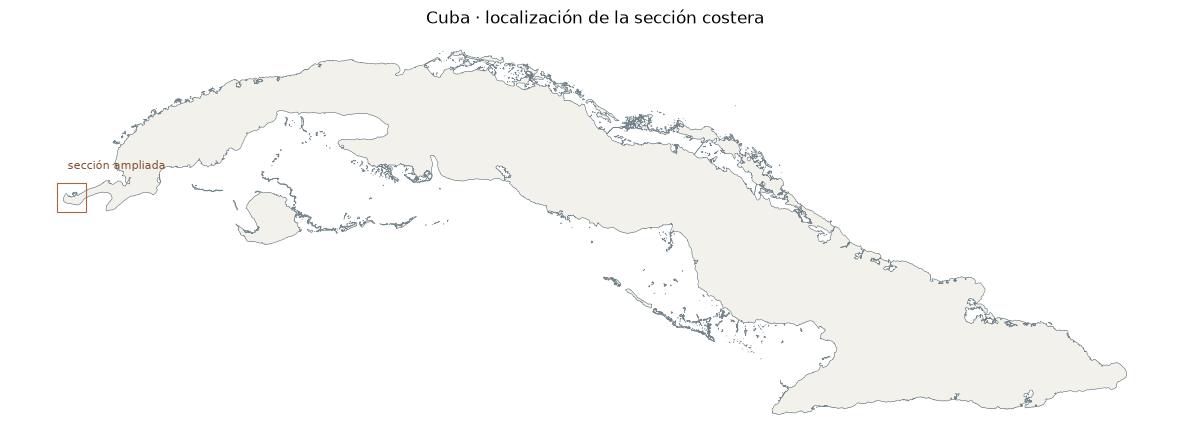

In [45]:
fig, ax = plt.subplots(figsize=(12, 9))

land.plot(ax=ax, color="#F2F1EB", edgecolor="none", zorder=1)
coastline.plot(ax=ax, color="#74828A", linewidth=0.35, zorder=2)
ax.add_patch(Rectangle((west, south), east - west, north - south,
                       fill=False, edgecolor="#AD643D", linewidth=0.8, zorder=4))
ax.annotate("sección ampliada", xy=(west, north), xytext=(8, 10),
            textcoords="offset points", fontsize=8, color="#854C2D", zorder=5)

ax.set_title("Cuba · localización de la sección costera")
ax.set_axis_off()
fig.tight_layout()
plt.show()

# fig.savefig(ROOT / "examples/coastal_features_national.png", dpi=220, bbox_inches="tight")


## Names in the selected section

List the actual preferred names under lowercase Spanish category headings.
Geographic names retain their published capitalization. These explanatory
translations leave the source classification unchanged; category meanings are
documented in [GeoNames](https://www.geonames.org/export/codes.html) and
[Overture](https://docs.overturemaps.org/schema/reference/base/water/).

Every listed name belongs to a Point in the detail map. Names and object IDs
remain available in `section` for dataset lookup.


In [46]:
spanish_types = {
    'bay': 'Bahía',
    'cove': 'Caleta',
    'marine channel': 'Canal marino',
    'cape': 'Cabo / Punta',
    'shoal': 'Bajo',
    'tidal creek': 'Estero mareal',
    'reef': 'Arrecife',
    'estuary': 'Estuario',
    'channel': 'Canal natural',
    'inlet': 'Bocana / Entrada de mar',
    'stream mouth': 'Desembocadura de río',
    'marsh': 'Marisma / Humedal herbáceo',
    'anchorage': 'Fondeadero',
    'bight': 'Ensenada',
    'strait': 'Estrecho',
    'lagoon': 'Laguna',
    'salt pond': 'Estanque salino',
    'bank': 'Banco submarino',
    'harbor': 'Puerto',
    'dock': 'Dársena',
    'mangrove swamp': 'Manglar',
    'gulf': 'Golfo',
    'tidal channel': 'Canal de marea',
    'tidal flat': 'Llanura intermareal',
    'sound': 'Seno / Brazo de mar',
    'swamp': 'Pantano / Ciénaga',
    'seaplane landing area': 'Zona de amerizaje',
    'ditch mouth': 'Desembocadura de zanja',
    'salt evaporation ponds': 'Salinas de evaporación',
    'coral reef': 'Arrecife coralino',
}


In [47]:
section["categoría"] = section["object_type"].map(spanish_types)
listed_names = section.sort_values(["categoría", "preferred_name"])

name_lists = []
for category, group in listed_names.groupby("categoría", sort=True):
    entries = "\n".join(f"- {name}" for name in group["preferred_name"])
    name_lists.append(f"### {category}\n\n{entries}")
display(Markdown("\n\n".join(name_lists)))


### Bahía

- Ensenada El Cajón
- Ensenada Morros de Piedra
- Ensenada San Juán
- Ensenada de Cayo Triste
- Ensenada de Santa Cruz
- Ensenada de la Balandra

### Bocana / Entrada de mar

- Pasa La Majagua

### Cabo / Punta

- Cabo de San Antonio
- Punta El Cajón
- Punta del Holandés
- Punta del Muerto

### Caleta

- Caleta Los Cayuelos
- Ensenada de Bolondrón
- Ensenada del Carey

### Canal marino

- Canal de los Barcos
- Pasa El Correo

### Canal natural

- Pasa Sorda del Muerto

### Ensenada

- Caleta San Vicente
- Caleta de los Piojos

### Estero mareal

- Estero Balandro
- Estero El Gato
- Estero La Salina
- Estero Los Morros
- Estero Palma Sola
- Estero Santa Cruz

### Laguna

- Laguna Balandra
- Laguna Bolondrón
- Laguna Palma Sola
- Laguna Sacorroto
- Laguna Saltamadera
- Laguna Zapataclán
- Lagunata Tierra Fértil
- Lagunata de Caja

## Label the coastal section

Place each preferred name close to its Point, trying short offsets in eight
directions. All labels remain horizontal. No connecting lines or numbers are used.

The view fits the selected features with a small margin. Placement starts with longer names and tries offsets of 5–28 typographic
points to reduce overlaps.


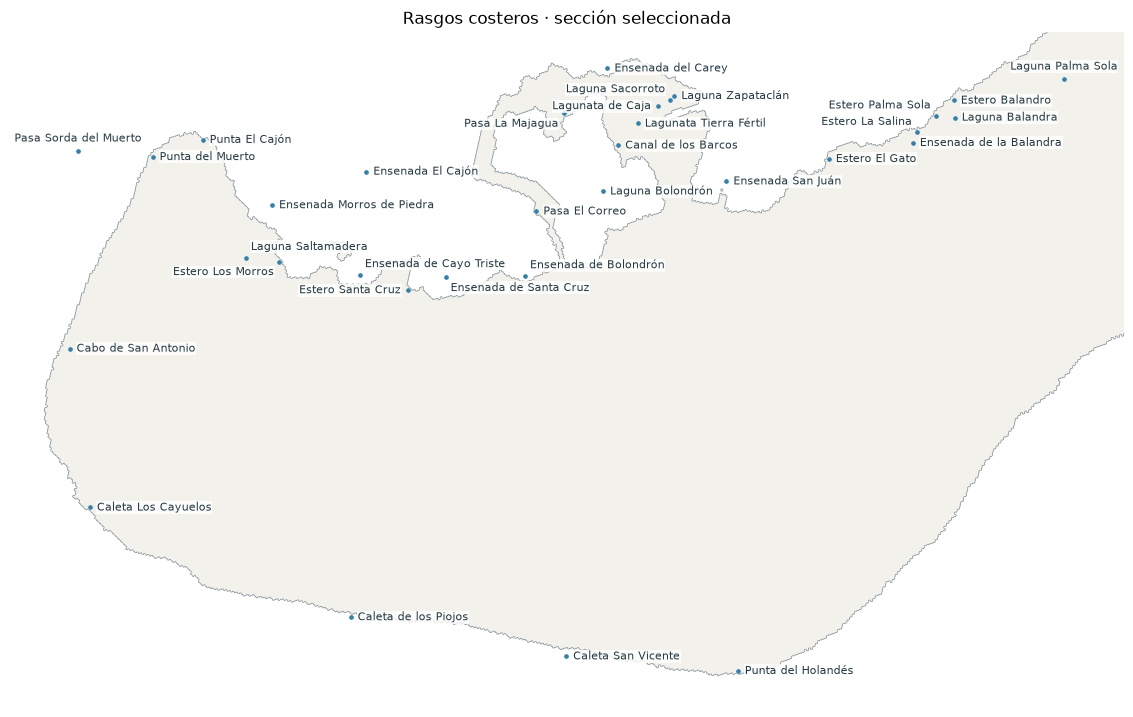

In [48]:
fig, ax = plt.subplots(figsize=(12, 9))

land.plot(ax=ax, color="#F2F1EB", edgecolor="none", zorder=1)
coastline.plot(ax=ax, color="#74828A", linewidth=0.45, zorder=2)
section.plot(ax=ax, color="#397FA3", markersize=14, edgecolor="white", linewidth=0.3, zorder=4)

xmin, ymin, xmax, ymax = section.total_bounds
width, height = xmax - xmin, ymax - ymin
ax.set_xlim(xmin - width * 0.06, xmax + width * 0.06)
ax.set_ylim(ymin - height * 0.06, ymax + height * 0.06)
ax.set_title("Rasgos costeros · sección seleccionada")
ax.set_axis_off()
fig.tight_layout()
fig.canvas.draw()

# Match the figure to the geographic extent instead of leaving blank canvas.
box = ax.get_position()
fig.set_size_inches(12, 12 * box.height / box.width * fig.get_figheight() / fig.get_figwidth())
fig.tight_layout()
fig.canvas.draw()

# Try short radial offsets around each point; reserve longer names first.
renderer = fig.canvas.get_renderer()
point_positions = ax.transData.transform(np.column_stack((section.geometry.x, section.geometry.y)))
placed_boxes = []
labels = section.sort_values("preferred_name", key=lambda values: values.str.len(), ascending=False)
angles = np.deg2rad(np.arange(0, 360, 45))

for row in labels.itertuples():
    label = ax.annotate(
        row.preferred_name, xy=(row.geometry.x, row.geometry.y),
        xytext=(0, 0), textcoords="offset points", fontsize=8, color="#263A43",
        rotation_mode="anchor",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=0.5), zorder=5,
    )
    best_score = np.inf
    for radius in [5, 9, 14, 20, 28]:
        for angle in angles:
            dx, dy = radius * np.cos(angle), radius * np.sin(angle)
            rotation = 0
            ha = "left" if dx > 1 else "right" if dx < -1 else "center"
            va = "bottom" if dy > 1 else "top" if dy < -1 else "center"
            label.set_rotation(rotation)
            label.set_position((dx, dy))
            label.set_ha(ha)
            label.set_va(va)
            box = label.get_window_extent(renderer).expanded(1.03, 1.25)
            overlap = sum(max(0, min(box.x1, old.x1) - max(box.x0, old.x0)) *
                          max(0, min(box.y1, old.y1) - max(box.y0, old.y0)) for old in placed_boxes)
            covered = sum(box.contains(x, y) for x, y in point_positions)
            outside = max(0, ax.bbox.x0 - box.x0) + max(0, box.x1 - ax.bbox.x1) + \
                      max(0, ax.bbox.y0 - box.y0) + max(0, box.y1 - ax.bbox.y1)
            score = overlap * 100 + covered * 10000 + outside * 1000 + radius + abs(rotation) * 0.5
            if score < best_score:
                best_score = score
                best_position = (dx, dy, ha, va, rotation)
    dx, dy, ha, va, rotation = best_position
    label.set_rotation(rotation)
    label.set_position((dx, dy))
    label.set_ha(ha)
    label.set_va(va)
    placed_boxes.append(label.get_window_extent(renderer).expanded(1.03, 1.25))

plt.show()

# fig.savefig(ROOT / "examples/coastal_features_section.png", dpi=220, bbox_inches="tight")


For name-object fields and the complete classification, see
[water geographic names](water_geographic_names.ipynb). For river and water-body
geometry, see [the hydrography map](hydrography_map.ipynb).
